# Browse the dataset

Pick a run from a generated dataset and look at it, as a still or as an animation over time. Run with
the `datagen/.venv` interpreter as the kernel.

Snapshot `i` is at `i × 1,000` years; there are 51 snapshots per run, from 0 to 50,000 years. In the
pictures, blue lines are rivers: nodes whose drainage area (the land upstream of them) is above
1,000 m².

In [1]:
from functools import cache

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image as ShowImage
from matplotlib.colors import LightSource
from PIL import Image

from erosion_datagen.config import ARTIFACTS_DIR
from erosion_datagen.render import render_frames, render_terrain
from erosion_datagen.simulate import dataset_dir, drainage_area, load_dataset
from erosion_datagen.config import PROFILES

In [2]:
@cache
def dataset(profile, split):
    return load_dataset(dataset_dir(PROFILES[profile], split))


def describe(params, run):
    return (f"K_ref={params['K_ref'][run]:.2e}  D/K_ref={params['D'][run] / params['K_ref'][run]:.2f}  "
            f"m={params['m'][run]:.2f}  U/K_ref={params['U'][run] / params['K_ref'][run]:.2f}  "
            f"period={params['period'][run]:.0f}  persistence={params['persistence'][run]:.2f}")


def hillshade(z, z_range=None):
    low, high = z_range if z_range is not None else (z.min(), z.max())
    light = LightSource(azdeg=315, altdeg=45)
    return light.shade(z, cmap=plt.cm.terrain, blend_mode="soft", vmin=low, vmax=high)

## 1. One sample

Set the profile, split, run, and snapshot, then run the cell. `INTERACTIVE = True` also opens a
window where the 3D view can be rotated with the mouse.

full/train run 0 of 8000, t = 50,000 yr
K_ref=4.67e-04  D/K_ref=0.37  m=0.38  U/K_ref=0.19  period=50  persistence=0.49


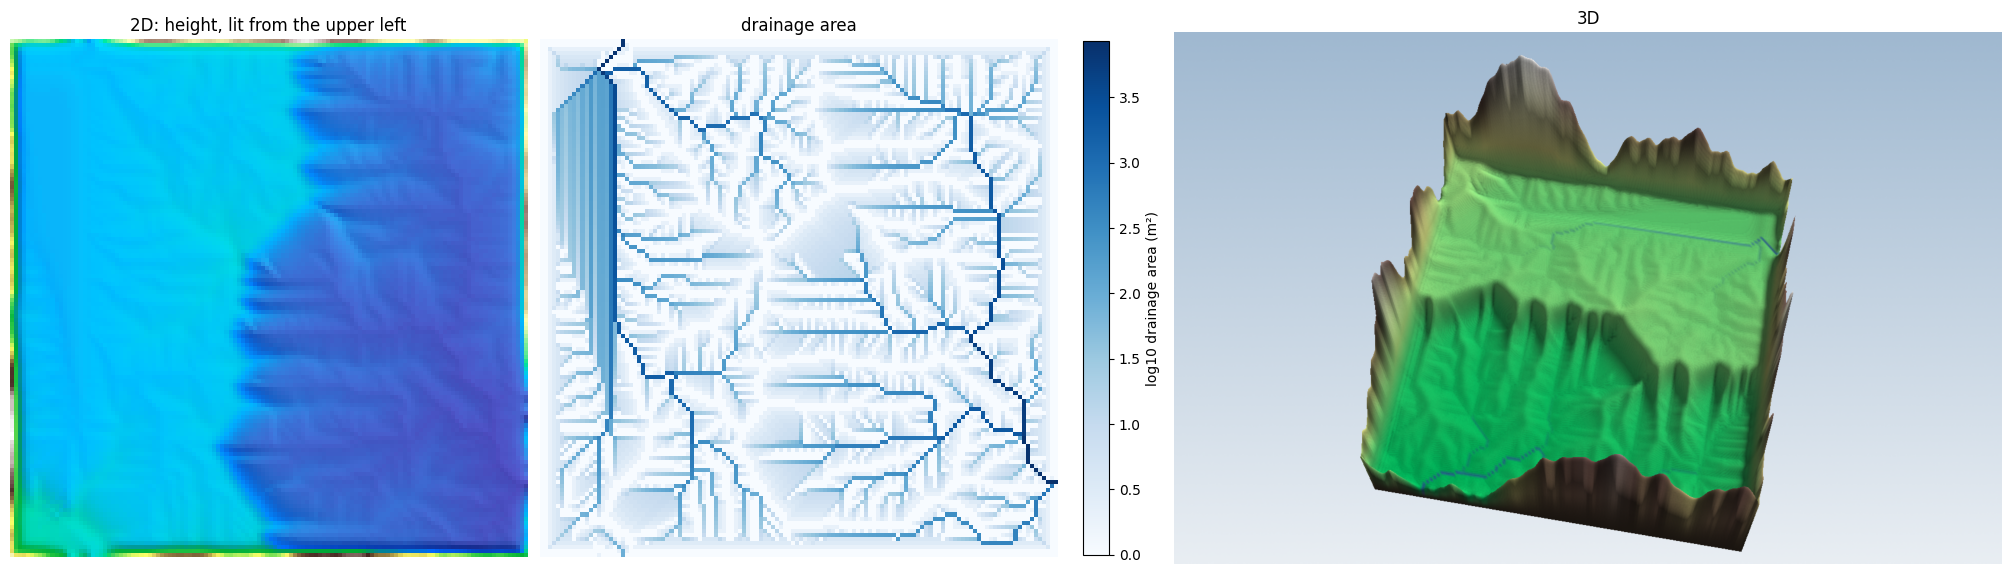

In [3]:
PROFILE, SPLIT = "full", "train"
RUN = 0
SNAPSHOT = 50  # 0 to 50
VERT_EXAG = 1.5  # vertical stretch for the 3D view
INTERACTIVE = False

snapshots, params, meta = dataset(PROFILE, SPLIT)
times = params["times"]
z = np.asarray(snapshots[RUN, SNAPSHOT], dtype=float)
area = drainage_area(z)
print(f"{PROFILE}/{SPLIT} run {RUN} of {len(snapshots)}, t = {times[SNAPSHOT]:,.0f} yr")
print(describe(params, RUN))

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), layout="constrained", width_ratios=[1, 1, 1.6])
axes[0].imshow(hillshade(z), origin="lower")
axes[0].set_title("2D: height, lit from the upper left")
im = axes[1].imshow(np.log10(np.maximum(area, 1.0)), origin="lower", cmap="Blues")
plt.colorbar(im, ax=axes[1], shrink=0.8, label="log10 drainage area (m²)")
axes[1].set_title("drainage area")
axes[2].imshow(render_terrain(z, area, vert_exag=VERT_EXAG))
axes[2].set_title("3D")
for ax in axes:
    ax.set_axis_off()
plt.show()

if INTERACTIVE:
    render_terrain(z, area, vert_exag=VERT_EXAG, interactive=True)

## 2. Animation over time

Renders every `EVERY`-th snapshot of one run, 2D on the left and 3D on the right, and saves a GIF to
`artifacts/animations/`. Every frame of a run shares one color scale and one camera, so only the
terrain changes. All 51 frames take about 10 seconds.

In [4]:
PROFILE, SPLIT = "full", "train"
RUN = 0
EVERY = 1  # use every n-th snapshot
FPS = 8
VERT_EXAG = 1.5

snapshots, params, meta = dataset(PROFILE, SPLIT)
times = params["times"][::EVERY]
zs = np.asarray(snapshots[RUN, ::EVERY], dtype=float)
areas = np.stack([drainage_area(z) for z in zs])
z_range = (zs.min(), zs.max())
print(describe(params, RUN))

frames_3d = render_frames(zs, areas, vert_exag=VERT_EXAG, window_size=(900, 640))
frames = []
for z, t, frame_3d in zip(zs, times, frames_3d):
    fig = plt.figure(figsize=(6.4, 6.4), dpi=100)
    ax = fig.add_axes([0, 0, 1, 0.93])
    ax.imshow(hillshade(z, z_range), origin="lower")
    ax.set_axis_off()
    fig.suptitle(f"run {RUN}, t = {t:,.0f} yr", fontsize=14, y=0.98)
    fig.canvas.draw()
    frame_2d = np.asarray(fig.canvas.buffer_rgba())[..., :3]
    plt.close(fig)
    frames.append(Image.fromarray(np.concatenate([frame_2d, frame_3d], axis=1)))

out = ARTIFACTS_DIR / "animations" / f"{PROFILE}-{SPLIT}-run{RUN}.gif"
out.parent.mkdir(parents=True, exist_ok=True)
frames[0].save(out, save_all=True, append_images=frames[1:], duration=int(1000 / FPS), loop=0)
print(f"saved {out} ({out.stat().st_size / 1e6:.1f} MB)")
ShowImage(filename=out)

K_ref=4.67e-04  D/K_ref=0.37  m=0.38  U/K_ref=0.19  period=50  persistence=0.49


saved /home/jay/Work/repos/erosion-sim-modeling/artifacts/animations/full-train-run0.gif (10.4 MB)
